# Experiment 8: Particle Swarm Optimization (PSO)

**Aim:** To implement a simple Particle Swarm Optimization algorithm for solving an optimization problem using Python.

**Theory:** PSO is a swarm-based optimiser in which each particle moves through the search space using its own best position (pbest) and the swarm's best position (gbest). Update rules: v = w·v + c1·r1·(pbest − x) + c2·r2·(gbest − x) and x = x + v. Problem: minimise the Sphere function f(x, y) = x² + y².

**Step 0:** Import the required libraries and fix the random seed.

In [1]:
import random, numpy as np
import matplotlib.pyplot as plt
random.seed(42); np.random.seed(42)

**Step 1:** Define the objective function.

In [2]:
def sphere(x): return float(np.sum(np.square(x)))

**Step 2:** Implement PSO (initialise particles, update velocity and position, track pbest and gbest).

In [3]:
def pso(func, dim=2, n=30, iters=60, w=0.7, c1=1.5, c2=1.5, lo=-10, hi=10):
    x = np.random.uniform(lo, hi, (n, dim)); v = np.zeros((n, dim))
    pbest = x.copy(); pbest_f = np.array([func(i) for i in x])
    g = pbest[pbest_f.argmin()].copy(); gf = pbest_f.min(); hist = [gf]
    for _ in range(iters):
        r1, r2 = np.random.rand(n, dim), np.random.rand(n, dim)
        v = w*v + c1*r1*(pbest-x) + c2*r2*(g-x)
        x = np.clip(x+v, lo, hi)
        f = np.array([func(i) for i in x])
        better = f < pbest_f
        pbest[better], pbest_f[better] = x[better], f[better]
        if pbest_f.min() < gf: gf = pbest_f.min(); g = pbest[pbest_f.argmin()].copy()
        hist.append(gf)
    return g, gf, hist

**Step 3:** Run PSO and print the result.

In [4]:
g, gf, hist = pso(sphere)
print("Best position:", np.round(g, 6)); print("Best value   :", gf)

Best position: [-1.16e-04 -5.10e-05]
Best value   : 1.6065849131510433e-08


**Step 4:** Plot the convergence.

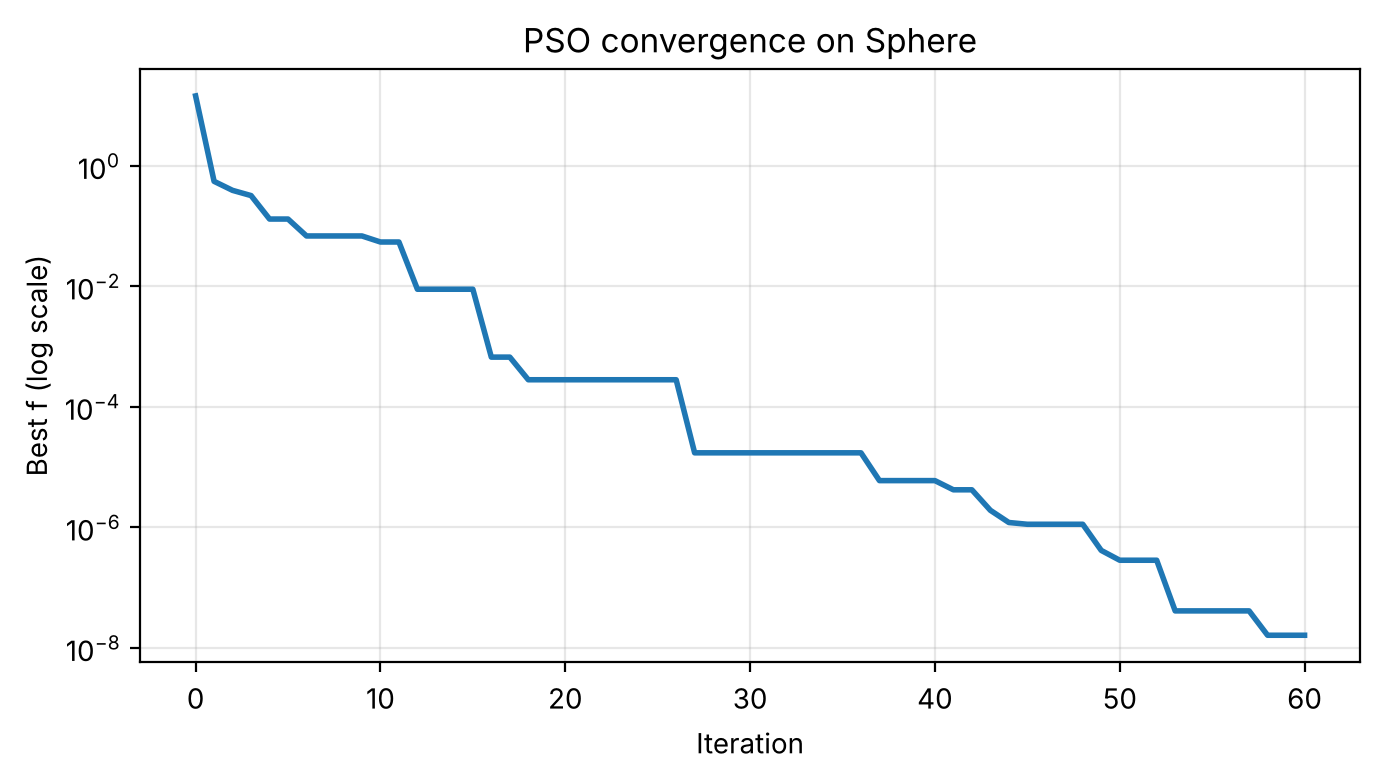

In [5]:
plt.figure(figsize=(7,4)); plt.semilogy(hist, lw=2)
plt.xlabel("Iteration"); plt.ylabel("Best f (log scale)"); plt.title("PSO convergence on Sphere")
plt.grid(alpha=.3); plt.tight_layout(); plt.show()